

Cost:  2.618782303613923

Beta 0 and 1 Values:  0.0427806044783092 2.825441790813474


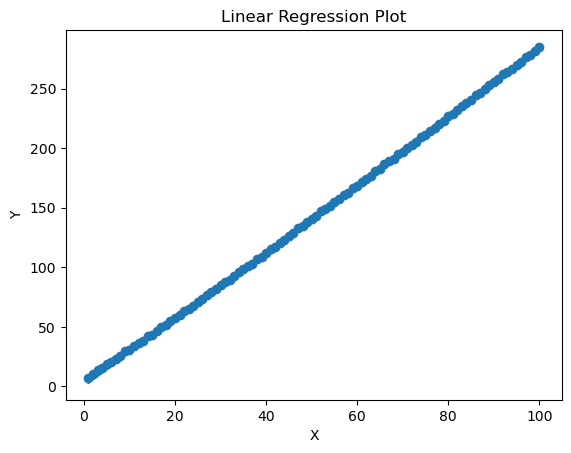

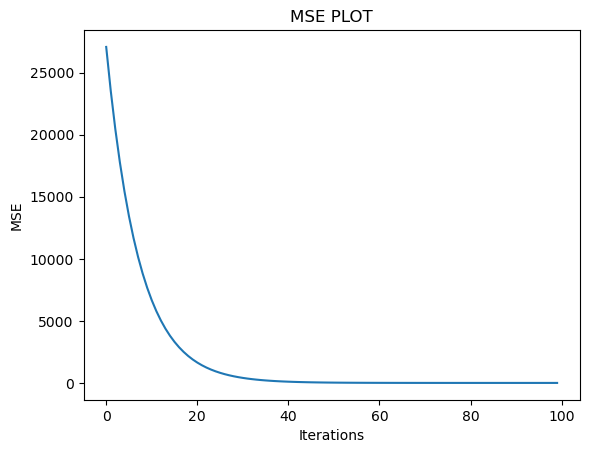

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#x = [ 1, 2, 3, 4, 5, 6]
#y = [0.3, 0.8, 0.61, 0.48, 0.18, 0.72]
x = list(range(1, 101))

y = [
    7.4, 10.1, 13.5, 15.2, 18.8, 20.7, 23.1, 25.6, 29.3, 30.5,
    33.7, 36.4, 38.2, 42.0, 43.5, 46.1, 49.7, 51.2, 54.8, 57.0,
    59.5, 63.4, 64.9, 67.7, 71.2, 73.0, 76.8, 79.1, 81.5, 84.7,
    87.9, 89.3, 93.0, 95.6, 98.2, 101.4, 103.1, 107.3, 109.0, 111.8,
    115.7, 117.0, 120.6, 123.2, 126.4, 129.1, 132.8, 134.3, 137.7, 140.2,
    142.8, 146.9, 148.5, 151.4, 154.7, 157.1, 160.5, 162.2, 166.8, 168.0,
    171.9, 174.4, 177.0, 180.6, 182.1, 186.5, 188.8, 191.3, 195.0, 196.7,
    200.4, 202.8, 205.3, 209.7, 211.0, 214.6, 217.2, 220.5, 223.1, 226.8,
    228.9, 232.0, 235.6, 238.1, 240.7, 244.5, 246.2, 250.0, 252.7, 255.4,
    258.0, 261.9, 264.3, 266.8, 270.1, 272.7, 276.5, 278.2, 281.6, 285.0
]

data = pd.Series(y, index = x)

mseplot = {}
#print(data)

#intial values
b0 = 0
b1 = 0
alpha = 0.00001 #step size
esum = 0
exsum =0

count = len(data.keys())

def cost(b0,b1):
    mse = 0
    esum = 0
    exsum =0
    for xi in data.keys():
        yi = b0 + b1*xi
        e = yi - data[xi]
        mse += e*e
        esum +=e
        exsum += e*xi
    mse /= count
    #print("\n\nCost: ",mse)
    return esum, exsum, mse

def gdes(b0,b1,esum,exsum):
    b0 = b0 - alpha*(2*esum)/count
    b1 = b1 - alpha*(2*exsum)/count
    return b0, b1

for i in range(100):
    esum,exsum,mse=cost(b0,b1)
    b0, b1 = gdes(b0,b1,esum,exsum)
    mseplot[i] = mse
    #print("\nBeta 0 and 1 Values: ",b0, b1)
    if esum == 0:
        break

print("\n\nCost: ",mse)
print("\nBeta 0 and 1 Values: ",b0, b1)

xline = np.linspace(min(x),max(x),100)
yline = b0 +b1*xline
plt.scatter(x,y)
plt.plot(xline,yline)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression Plot")
plt.show()


xline = mseplot.keys()#np.linspace(min(mseplot.keys()),max(mseplot.keys(),100))
yline = mseplot.values()
plt.plot(xline,yline)
plt.xlabel("Iterations")
plt.ylabel("MSE")
plt.title("MSE PLOT")
plt.show()
